In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    raise RuntimeError(
        "GPU is not enabled. Go to Runtime > Change runtime type > T4 GPU."
    )

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:


import sys
import subprocess


import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU not detected. Enable T4 GPU in Colab first."
    )

print("GPU detected:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)


print("\nRemoving conflicting legacy Gemini packages...")

subprocess.run(
    [
        sys.executable, "-m", "pip", "uninstall", "-y",
        "google-generativeai",
        "google-ai-generativelanguage"
    ],
    check=False
)


core_packages = [
    "transformers==4.57.3",
    "trl==0.24.0",
    "peft==0.17.1",
    "accelerate==1.11.0",
    "datasets==4.3.0",
    "protobuf==6.31.1",
    "pandas>=2.2,<3",
    "matplotlib>=3.9,<4",
    "psutil"
]

print("\nInstalling core RL dependencies...")

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        *core_packages
    ],
    check=True
)


eval_dependencies = [
    "wget",
    "tempdir",
    "multipledispatch",
    "appdirs",
    "numpy",
    "tqdm",
    "termcolor",
    "fire",
    "tree-sitter>=0.22.0",
    "tree-sitter-python>=0.21.0",
    "rich",
    "stop-sequencer"
]

print("\nInstalling local evaluation dependencies...")

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        *eval_dependencies
    ],
    check=True
)


print("\nInstalling EvalPlus...")

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "evalplus==0.3.1",
        "--no-deps"
    ],
    check=True
)

print("\n======================================")
print("GPU ENVIRONMENT PACKAGES INSTALLED")
print("======================================")
print("IMPORTANT: Restart the Colab session now.")


GPU detected: Tesla T4
PyTorch: 2.11.0+cu130

Removing conflicting legacy Gemini packages...

Installing core RL dependencies...

Installing local evaluation dependencies...

Installing EvalPlus...

GPU ENVIRONMENT PACKAGES INSTALLED
IMPORTANT: Restart the Colab session now.


In [ ]:


import os
import sys
import gc
import ast
import copy
import csv
import gzip
import hashlib
import html
import json
import math
import random
import re
import tempfile
import textwrap
import time
import urllib.request

from pathlib import Path
from functools import lru_cache
from datetime import datetime, timezone
from IPython.display import display

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import importlib.metadata as metadata

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainerCallback,
    set_seed
)

from peft import LoraConfig, get_peft_model
from trl import GRPOConfig, GRPOTrainer
from datasets import Dataset


PINS = {
    "transformers": "4.57.3",
    "trl": "0.24.0",
    "peft": "0.17.1",
    "accelerate": "1.11.0",
    "datasets": "4.3.0",
    "evalplus": "0.3.1"
}


if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU unavailable. Enable T4 GPU in Colab and restart."
    )

DEVICE = "cuda"

DEVICE_NAME = torch.cuda.get_device_name(0)

GPU_PROPERTIES = torch.cuda.get_device_properties(0)

GPU_MEMORY_GB = (
    GPU_PROPERTIES.total_memory / (1024 ** 3)
)


USE_BF16 = torch.cuda.is_bf16_supported()

USE_FP16 = not USE_BF16

MODEL_DTYPE = (
    torch.bfloat16 if USE_BF16
    else torch.float16
)

torch.backends.cuda.matmul.allow_tf32 = True


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

set_seed(SEED)


MODEL_NAME = "Qwen/Qwen2.5-Coder-0.5B-Instruct"

TASK_IDS = [
    "HumanEval/22",
    "HumanEval/25",
    "HumanEval/44",
    "HumanEval/48"
]

STEPS_PER_STAGE = 5
STAGES = 2

WEAK_TEST_COUNT = 1
CHALLENGE_TEST_COUNT = 6

EVAL_SAMPLES_PER_TASK = 2
PROBE_SAMPLES_PER_TASK = 2

MAX_NEW_TOKENS = 256

WEIGHTS = {
    "Pw": 0.40,
    "Pc": 0.35,
    "Mw": 0.15,
    "V": 0.10
}

MODEL_REVISION = None

run_name = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f"
)



def create_output_directory():

    path = (
        Path.cwd()
        / "BAGR_project_results"
        / run_name
    )

    try:
        path.mkdir(parents=True, exist_ok=False)

    except OSError:
        path = Path(
            tempfile.mkdtemp(prefix="BAGR_results_")
        )

    folders = [
        "data",
        "candidates",
        "checkpoints",
        "logs",
        "results",
        "figures"
    ]

    for folder in folders:
        (path / folder).mkdir(exist_ok=True)

    return path


OUTPUT_DIR = create_output_directory()



def clear_device_cache():

    gc.collect()
    torch.cuda.empty_cache()


def reset_memory_stats():

    torch.cuda.reset_peak_memory_stats()


def memory_stats():

    return {
        "GPU": DEVICE_NAME,
        "Peak CUDA GB": (
            torch.cuda.max_memory_allocated() / 1024**3
        ),
        "Reserved CUDA GB": (
            torch.cuda.max_memory_reserved() / 1024**3
        ),
        "Process RSS GB": (
            psutil.Process().memory_info().rss / 1024**3
        )
    }


def worker_environment():

    keys = [
        "PATH",
        "SYSTEMROOT",
        "WINDIR",
        "TEMP",
        "TMP",
        "TMPDIR",
        "HOME",
        "USERPROFILE",
        "APPDATA",
        "LOCALAPPDATA",
        "HOMEDRIVE",
        "HOMEPATH"
    ]

    env = {
        key: os.environ[key]
        for key in keys
        if key in os.environ
    }

    env.update(
        LANG="C.UTF-8",
        OMP_NUM_THREADS="1"
    )

    return env


def save_json(filename, value):

    (OUTPUT_DIR / filename).write_text(
        json.dumps(
            value,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        ),
        encoding="utf-8"
    )


def save_csv(filename, rows):

    if rows:

        pd.DataFrame(rows).to_csv(
            OUTPUT_DIR / filename,
            index=False
        )


def display_table(rows, title=""):

    print(title)
    display(pd.DataFrame(rows))



installed_packages = {}

for name in PINS:

    try:
        installed_packages[name] = metadata.version(name)

    except metadata.PackageNotFoundError:
        installed_packages[name] = "Not installed"


settings = {
    "model": MODEL_NAME,
    "tasks": TASK_IDS,
    "seed": SEED,
    "steps_per_stage": STEPS_PER_STAGE,
    "stages": STAGES,
    "optimizer_restart_each_stage": True,
    "weak_tests": WEAK_TEST_COUNT,
    "challenge_tests": CHALLENGE_TEST_COUNT,
    "eval_samples_per_task": EVAL_SAMPLES_PER_TASK,
    "probe_samples_per_task": PROBE_SAMPLES_PER_TASK,
    "generation_max_tokens": MAX_NEW_TOKENS,
    "temperature": 0.8,
    "top_p": 0.95,
    "top_k": 0,
    "repetition_penalty": 1.0,
    "weights": WEIGHTS,
    "packages": installed_packages,
    "torch": torch.__version__,
    "device": DEVICE,
    "device_name": DEVICE_NAME,
    "gpu_memory_gb": GPU_MEMORY_GB,
    "base_dtype": str(MODEL_DTYPE)
}

save_json("settings.json", settings)



print("\n" + "=" * 55)
print("       BAGR PROJECT - GPU ENVIRONMENT READY")
print("=" * 55)

print("Model:", MODEL_NAME)
print("Device:", DEVICE)
print("GPU:", DEVICE_NAME)
print("GPU Memory:", round(GPU_MEMORY_GB, 2), "GB")
print("PyTorch:", torch.__version__)
print("Model dtype:", MODEL_DTYPE)
print("BF16 supported:", USE_BF16)
print("FP16 enabled:", USE_FP16)

print("\nPackage Versions:")

for name, version in installed_packages.items():
    print(f"{name}: {version}")

print("\nProject Configuration:")
print("Tasks:", TASK_IDS)
print("Stages:", STAGES)
print("Steps per stage:", STEPS_PER_STAGE)
print("Weak tests:", WEAK_TEST_COUNT)
print("Challenge tests:", CHALLENGE_TEST_COUNT)

print("\nGPU Memory:")
print(memory_stats())

print("\nResults directory:")
print(OUTPUT_DIR.resolve())

print("\n" + "=" * 55)
print("GPU INITIALIZATION SUCCESSFUL!")
print("=" * 55)



       BAGR PROJECT - GPU ENVIRONMENT READY
Model: Qwen/Qwen2.5-Coder-0.5B-Instruct
Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB
PyTorch: 2.11.0+cu130
Model dtype: torch.bfloat16
BF16 supported: True
FP16 enabled: False

Package Versions:
transformers: 4.57.3
trl: 0.24.0
peft: 0.17.1
accelerate: 1.11.0
datasets: 4.3.0
evalplus: 0.3.1

Project Configuration:
Tasks: ['HumanEval/22', 'HumanEval/25', 'HumanEval/44', 'HumanEval/48']
Stages: 2
Steps per stage: 5
Weak tests: 1
Challenge tests: 6

GPU Memory:
{'GPU': 'Tesla T4', 'Peak CUDA GB': 4.76837158203125e-07, 'Reserved CUDA GB': 0.001953125, 'Process RSS GB': 1.6703948974609375}

Results directory:
/content/BAGR_project_results/20261101_165302_873761

GPU INITIALIZATION SUCCESSFUL!


In [ ]:
import os, sys, subprocess, importlib.metadata as metadata

os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')
PINS = {'transformers':'4.57.3', 'trl':'0.24.0', 'peft':'0.17.1',
        'accelerate':'1.11.0', 'datasets':'4.3.0', 'evalplus':'0.3.1'}
stale = []
requirements = [name+'=='+version for name,version in PINS.items()]
for name,version in PINS.items():
    try:
        installed = metadata.version(name)
    except metadata.PackageNotFoundError:
        installed = None
    if name in sys.modules and installed != version:
        stale.append(name)
try:
    torch_version = metadata.version('torch')
    torch_numbers = tuple(int(value) for value in torch_version.split('+')[0].split('.')[:2])
except metadata.PackageNotFoundError:
    torch_numbers = (0,0)
if torch_numbers < (2,6):
    requirements.append('torch==2.9.0')
    if 'torch' in sys.modules:
        stale.append('torch')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *requirements,
                'pandas>=2.2,<3', 'matplotlib>=3.9,<4'], check=True)
if stale:
    raise RuntimeError('Dependencies installed. Restart the notebook kernel, then Run all. Previously imported: '+', '.join(stale))

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, TrainerCallback, set_seed
from peft import LoraConfig, get_peft_model
from trl import GRPOConfig, GRPOTrainer
from datasets import Dataset
import pandas as pd
import matplotlib.pyplot as plt
import psutil

REQUESTED_DEVICE = 'auto'  # auto, cpu, cuda, or mps; keep auto for normal use

def detect_device(requested='auto'):
    available = {'cpu':True, 'cuda':torch.cuda.is_available(),
                 'mps':hasattr(torch.backends,'mps') and torch.backends.mps.is_available()}
    if requested != 'auto':
        if not available.get(requested,False):
            raise RuntimeError('Requested device is unavailable: '+requested)
        return requested
    if available['cuda']:
        return 'cuda'
    if available['mps']:
        try:
            probe = torch.ones(2,device='mps',requires_grad=True)
            probe.square().sum().backward()
            del probe
            torch.mps.empty_cache()
            return 'mps'
        except RuntimeError as error:
            print('MPS initialization failed; using CPU:',str(error)[:200])
    return 'cpu'

DEVICE = detect_device(REQUESTED_DEVICE)
USE_FP16 = DEVICE == 'cuda'
MODEL_DTYPE = torch.float16 if USE_FP16 else torch.float32
DEVICE_NAME = torch.cuda.get_device_name() if DEVICE=='cuda' else 'Apple MPS' if DEVICE=='mps' else 'CPU'
print('Device:',DEVICE_NAME,'| base dtype:',MODEL_DTYPE,'| PyTorch:',torch.__version__)
if DEVICE=='cpu':
    print('CPU uses the same real RL pipeline. Expect a substantially longer run; 16 GB RAM is recommended.')
print({name:metadata.version(name) for name in PINS})

### Step 2 — Small, controlled experiment settings

Every training method receives the same model, seed, LoRA configuration, generation
settings, challenge budget, and number of updates. The run has two five-step stages;
the current policy is sampled between them and adaptive tests are refreshed.
For simplicity, each stage creates a fresh optimizer. This restart is identical
for all methods and is recorded as part of the experimental protocol.

In [ ]:
import ast, copy, csv, gzip, hashlib, html, json, math, os, random, re
import tempfile, textwrap, time, urllib.request, gc
from pathlib import Path
from functools import lru_cache
from datetime import datetime, timezone
from IPython.display import display

MODEL_NAME = 'Qwen/Qwen2.5-Coder-0.5B-Instruct'
TASK_IDS = ['HumanEval/22','HumanEval/25','HumanEval/44','HumanEval/48']
SEED = 42
STEPS_PER_STAGE = 5
STAGES = 2
WEAK_TEST_COUNT = 1
CHALLENGE_TEST_COUNT = 6
EVAL_SAMPLES_PER_TASK = 2
PROBE_SAMPLES_PER_TASK = 2
MAX_NEW_TOKENS = 256
WEIGHTS = {'Pw':.40, 'Pc':.35, 'Mw':.15, 'V':.10}
MODEL_REVISION = None
run_name = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
def create_output_directory():
    path = Path.cwd() / 'BAGR_project_results' / run_name
    try:
        path.mkdir(parents=True,exist_ok=False)
    except OSError:
        path = Path(tempfile.mkdtemp(prefix='BAGR_results_'))
    for folder in ['data','candidates','checkpoints','logs','results','figures']:
        (path / folder).mkdir(exist_ok=True)
    return path

OUTPUT_DIR = create_output_directory()

def clear_device_cache():
    gc.collect()
    if DEVICE=='cuda':
        torch.cuda.empty_cache()
    elif DEVICE=='mps':
        torch.mps.empty_cache()

def reset_memory_stats():
    if DEVICE=='cuda':
        torch.cuda.reset_peak_memory_stats()

def memory_stats():
    return {'Peak CUDA GB':torch.cuda.max_memory_allocated()/1024**3 if DEVICE=='cuda' else None,
            'MPS allocated GB':torch.mps.current_allocated_memory()/1024**3 if DEVICE=='mps' else None,
            'Process RSS GB':psutil.Process().memory_info().rss/1024**3}

def worker_environment():
 
    keys = ['PATH','SYSTEMROOT','WINDIR','TEMP','TMP','TMPDIR','HOME','USERPROFILE',
            'APPDATA','LOCALAPPDATA','HOMEDRIVE','HOMEPATH']
    env = {key:os.environ[key] for key in keys if key in os.environ}
    env.update(LANG='C.UTF-8',OMP_NUM_THREADS='1')
    return env

def save_json(filename, value):
    (OUTPUT_DIR / filename).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False),encoding='utf-8')

def save_csv(filename, rows):
    if rows:
        pd.DataFrame(rows).to_csv(OUTPUT_DIR / filename, index=False)

def display_table(rows, title=''):
    print(title)
    display(pd.DataFrame(rows))

save_json('settings.json', {'model':MODEL_NAME, 'tasks':TASK_IDS, 'seed':SEED,
    'steps_per_stage':STEPS_PER_STAGE, 'stages':STAGES, 'optimizer_restart_each_stage':True,
    'weak_tests':WEAK_TEST_COUNT, 'challenge_tests':CHALLENGE_TEST_COUNT,
    'eval_samples_per_task':EVAL_SAMPLES_PER_TASK, 'generation_max_tokens':MAX_NEW_TOKENS,
    'temperature':.8, 'top_p':.95, 'top_k':0, 'repetition_penalty':1.0,
    'packages':{name:metadata.version(name) for name in PINS}, 'torch':torch.__version__,
    'device':DEVICE, 'device_name':DEVICE_NAME, 'base_dtype':str(MODEL_DTYPE)})
print('Results directory:', OUTPUT_DIR.resolve())

Results directory: /content/BAGR_project_results/20261101_165355_250279


### Step 3 — Load official public HumanEval

The training records come from the original public HumanEval release. EvalPlus
HumanEval+ utilities are used later, inside the independent final evaluator.
Separating these loaders keeps hidden `plus_input` and hidden failure examples out
of challenge generation and training rewards. No embedded dataset is substituted.

In [ ]:
PUBLIC_URL = 'https://raw.githubusercontent.com/openai/human-eval/master/data/HumanEval.jsonl.gz'
with urllib.request.urlopen(PUBLIC_URL, timeout=60) as response:
    public_bytes = response.read()
public_tasks = {row['task_id']:row for row in
                (json.loads(line) for line in gzip.decompress(public_bytes).decode().splitlines())}
problems = {task:public_tasks[task] for task in TASK_IDS}
assert all('plus_input' not in problem for problem in problems.values())
save_json('data/public_tasks.json', problems)
save_json('data/provenance.json', {'source':PUBLIC_URL, 'sha256':hashlib.sha256(public_bytes).hexdigest()})
display_table([{'Task ID':task, 'Function':problems[task]['entry_point']} for task in TASK_IDS], 'Official tasks')

Official tasks


,Task ID,Function
0,HumanEval/22,filter_integers
1,HumanEval/25,factorize
2,HumanEval/44,change_base
3,HumanEval/48,is_palindrome


### Step 4 — Extract public tests and their expected outputs

The trusted public `check` function runs with a recording reference function,
capturing even inputs constructed in loops. Weak-1/3/5 use nested prefixes.
Weak-5 is N/A when the task has fewer than five public tests.

HumanEval/22's reference includes booleans through `isinstance(x, int)`.
We preserve the actual benchmark behavior instead of redefining the task.

In [ ]:
def collect_public_tests(problem):
    namespace = {}
    exec(problem['prompt'] + problem['canonical_solution'], namespace)
    reference = namespace[problem['entry_point']]
    inputs = []
    expected = []

    def recording_reference(*arguments):
        inputs.append(copy.deepcopy(list(arguments)))
        result = reference(*copy.deepcopy(arguments))
        expected.append(copy.deepcopy(result))
        return result

    exec(problem['test'], namespace)
    namespace['check'](recording_reference)
    return inputs, expected

public_inputs = {}
public_expected = {}
for task in TASK_IDS:
    public_inputs[task], public_expected[task] = collect_public_tests(problems[task])

display_table([{'Task ID': task, 'Public tests': len(public_inputs[task]),
                'Weak-5 eligible': len(public_inputs[task]) >= 5}
               for task in TASK_IDS], 'Available public tests')
assert all(len(public_inputs[task]) >= WEAK_TEST_COUNT for task in TASK_IDS)

Available public tests


,Task ID,Public tests,Weak-5 eligible
0,HumanEval/22,3,False
1,HumanEval/25,8,True
2,HumanEval/44,12,True
3,HumanEval/48,7,True


### Step 5 — A reusable bounded code executor

Generated programs run in separate processes with per-input time budgets, parent wall
timeouts, restricted builtins, and allowed imports. Unix uses signal timers and resource
limits. Windows runs one input per process and measures elapsed time; its parent watchdog
kills hanging calls. Unix-specific resource limits are applied only where available. Expected
answers never enter the candidate process. Runtime failures and wrong answers are
different outcomes. Use a disposable runtime without sensitive mounted files;
this research helper is not a hardened operating-system security sandbox.

In [ ]:
WORKER_CODE = r'''
import ast, builtins, copy, json, math, signal, sys, time
try:
    import resource
except ImportError:
    resource = None
HAS_TIMERS = hasattr(signal,'SIGALRM') and hasattr(signal,'setitimer')
ALLOWED_IMPORTS = {'math','typing','collections','itertools','functools','string','statistics','heapq','bisect'}
FORBIDDEN = {'open','exec','eval','compile','globals','locals','vars','getattr','setattr','delattr','input',
             'os','sys','subprocess','socket','builtins','resource','signal','help','exit','quit','__import__'}

def import_allowed(name,globals=None,locals=None,fromlist=(),level=0):
    if level or name not in ALLOWED_IMPORTS:
        raise ImportError('Import not allowed')
    return builtins.__import__(name,globals,locals,fromlist,level)

def timeout(signum,frame):
    raise TimeoutError('Execution timeout')

def arm(seconds):
    if HAS_TIMERS:
        signal.setitimer(signal.ITIMER_REAL,seconds)

def main():
    request = json.load(sys.stdin)
    if resource:
        cpu = max(2,math.ceil(len(request['inputs'])*.5)+2)
        resource.setrlimit(resource.RLIMIT_CPU,(cpu,cpu))
        resource.setrlimit(resource.RLIMIT_FSIZE,(1000000,1000000))
        if sys.platform.startswith('linux'):
            resource.setrlimit(resource.RLIMIT_AS,(256*1024**2,256*1024**2))
    names = ('abs all any bool chr dict divmod enumerate filter float int isinstance iter len list map max min next '
             'ord pow range repr reversed round set sorted str sum tuple type zip Exception ValueError TypeError '
             'ZeroDivisionError StopIteration AssertionError').split()
    allowed = {name:getattr(builtins,name) for name in names}
    allowed.update(__import__=import_allowed,print=lambda *args,**kwargs:None)
    namespace = {'__builtins__':allowed,'__name__':'candidate'}
    if HAS_TIMERS:
        signal.signal(signal.SIGALRM,timeout)
    results = []
    try:
        tree = ast.parse(request['source'])
        for node in ast.walk(tree):
            if isinstance(node,ast.Name) and (node.id in FORBIDDEN or node.id.startswith('__')):
                raise ValueError('Disallowed name')
            if isinstance(node,ast.Attribute) and (node.attr.startswith('_') or node.attr in FORBIDDEN):
                raise ValueError('Disallowed attribute')
            if isinstance(node,ast.Import) and any(a.name not in ALLOWED_IMPORTS for a in node.names):
                raise ValueError('Disallowed import')
            if isinstance(node,ast.ImportFrom) and (node.level or node.module not in ALLOWED_IMPORTS):
                raise ValueError('Disallowed import')
        started = time.perf_counter()
        arm(.5)
        exec(compile(tree,'<candidate>','exec'),namespace)
        function = namespace[request['entry_point']]
        if time.perf_counter()-started > .5:
            raise TimeoutError('Execution timeout')
    except BaseException as error:
        results = [{'status':'timeout' if isinstance(error,TimeoutError) else 'invalid_code',
                    'output':None,'error':type(error).__name__} for _ in request['inputs']]
    else:
        arm(0)
        for arguments in request['inputs']:
            try:
                started = time.perf_counter()
                arm(.5)
                output = function(*copy.deepcopy(arguments))
                encoded = json.dumps(output,allow_nan=False)
                if time.perf_counter()-started > .5:
                    raise TimeoutError('Execution timeout')
                if len(encoded)>100000:
                    raise ValueError('Output too large')
                kind = request['entry_point']
                valid = ((isinstance(output,list) and all(isinstance(x,int) for x in output)) if kind in ('filter_integers','factorize')
                         else isinstance(output,str) if kind=='change_base' else isinstance(output,bool))
                results.append({'status':'ok' if valid else 'invalid_output',
                                'output':json.loads(encoded) if valid else None,'error':None})
            except BaseException as error:
                results.append({'status':'timeout' if isinstance(error,TimeoutError) else 'runtime_error',
                                'output':None,'error':type(error).__name__})
            finally:
                arm(0)
    arm(0)
    json.dump(results,sys.stdout)

if __name__=='__main__':
    main()

'''

def clean_code(completion):
    text = str(completion).strip('\r\n')
    blocks = re.findall(r'```(?:python)?\s*\n(.*?)```', text, flags=re.DOTALL)
    return blocks[0].strip('\r\n') if blocks else text

def complete_source(task, completion):
    code_text = clean_code(completion)
    problem = problems[task]
    try:
        tree = ast.parse(textwrap.dedent(code_text))
        if any(isinstance(node, ast.FunctionDef) and node.name == problem['entry_point'] for node in tree.body):
            imports = problem['prompt'].split('def ' + problem['entry_point'])[0]
            return imports + textwrap.dedent(code_text)
    except SyntaxError:
        pass
    body = code_text if code_text.startswith((' ', '\t')) else textwrap.indent(code_text, '    ')
    return problem['prompt'] + body + '\n'


def run_worker_request(request):
    try:
        with tempfile.TemporaryDirectory() as directory:
            worker = Path(directory)/'worker.py'
            worker.write_text(WORKER_CODE,encoding='utf-8')
            process = subprocess.run([sys.executable,'-X','utf8','-I','-S',str(worker)],
                input=json.dumps(request),capture_output=True,text=True,encoding='utf-8',cwd=directory,
                env=worker_environment(),timeout=3+.5*len(request['inputs']))
        if process.returncode!=0:
            raise RuntimeError(process.stderr[-200:])
        results = json.loads(process.stdout)
        if len(results)!=len(request['inputs']):
            raise RuntimeError('Incomplete execution results')
        return results
    except subprocess.TimeoutExpired:
        return [{'status':'timeout','output':None,'error':'Wall timeout'} for _ in request['inputs']]
    except Exception as error:
        return [{'status':'worker_error','output':None,'error':str(error)[:200]} for _ in request['inputs']]

@lru_cache(maxsize=512)
def cached_execution(task,completion,inputs_json):
    inputs = json.loads(inputs_json)
    request = {'source':complete_source(task,completion),'entry_point':problems[task]['entry_point'],'inputs':inputs}
    if os.name=='nt':
        return [result for arguments in inputs
                for result in run_worker_request(dict(request,inputs=[arguments]))]
    return run_worker_request(request)

def execute_candidate(task,completion,inputs):
    return copy.deepcopy(cached_execution(task,str(completion),json.dumps(inputs,sort_keys=True)))

def trusted_outputs(task,inputs):
    results = execute_candidate(task,problems[task]['canonical_solution'],inputs)
    assert all(result['status']=='ok' for result in results),(task,results)
    return [result['output'] for result in results]

print('Bounded execution helper ready for',os.name+'.')

Bounded execution helper ready for posix.


In [ ]:
import subprocess
for task in TASK_IDS:
    observed = trusted_outputs(task, public_inputs[task])
    assert observed == public_expected[task], task
print('All public reference outputs validated by the bounded executor.')

All public reference outputs validated by the bounded executor.


### Step 6 — Load Qwen and generate actual baseline programs

Only newly generated tokens are decoded. The same chat prompts and sampling seed
are used for every final model comparison. A malformed or truncated generation
remains in the evaluation denominator; it is never replaced by a reference solution.
The model's resolved Hugging Face commit is reused for all fresh training models.

In [ ]:
set_seed(SEED)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = 'left'
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

messages = {task:[{'role':'user', 'content':
    'Solve this Python problem. Return only the complete Python function and necessary imports. '
    'Use the exact function name and specified behavior.\n\n' + problems[task]['prompt']}]
    for task in TASK_IDS}
train_dataset = Dataset.from_list([{'task_id':task, 'prompt':messages[task]} for task in TASK_IDS])

def load_base_model():
    options = {'dtype':MODEL_DTYPE, 'low_cpu_mem_usage':True}
    if MODEL_REVISION is not None:
        options['revision'] = MODEL_REVISION
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **options).to(DEVICE)
    model.config.use_cache = False
    model.config.pad_token_id = tokenizer.pad_token_id
    return model

def sample_policy(model, count, seed, method):
    records = []
    was_training = model.training
    model.eval()
    try:
        with torch.random.fork_rng(devices=[torch.cuda.current_device()] if DEVICE=='cuda' else []):
            set_seed(seed)
            for task in TASK_IDS:
                prompt = tokenizer.apply_chat_template(messages[task], tokenize=False, add_generation_prompt=True)
                inputs = tokenizer(prompt, return_tensors='pt', add_special_tokens=False).to(model.device)
                for index in range(count):
                    with torch.inference_mode():
                        generated = model.generate(**inputs, do_sample=True, temperature=.8, top_p=.95,
                            top_k=0, repetition_penalty=1.0,
                            max_new_tokens=MAX_NEW_TOKENS, use_cache=True,
                            pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id)
                    new_tokens = generated[0, inputs['input_ids'].shape[-1]:]
                    completion = tokenizer.decode(new_tokens, skip_special_tokens=True)
                    records.append({'method':method, 'task_id':task, 'sample_id':index,
                                    'name':method, 'completion':completion,
                                    'token_limit_reached':len(new_tokens) >= MAX_NEW_TOKENS})
    finally:
        model.train(was_training)
    return records

def save_candidates(filename, candidates):
    with (OUTPUT_DIR / filename).open('w',encoding='utf-8') as file:
        for candidate in candidates:
            record = dict(candidate, solution=complete_source(candidate['task_id'], candidate['completion']))
            file.write(json.dumps(record, ensure_ascii=False) + '\n')

model = load_base_model()
MODEL_REVISION = getattr(model.config, '_commit_hash', None)
if MODEL_REVISION is None:
    raise RuntimeError('Unable to resolve the base-model revision for a controlled comparison.')
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)
tokenizer.padding_side = 'left'
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
save_json('model_revision.json', {'model':MODEL_NAME, 'revision':MODEL_REVISION})
baseline_candidates = sample_policy(model, EVAL_SAMPLES_PER_TASK, SEED+1000, 'E1')
baseline_probes = sample_policy(model, PROBE_SAMPLES_PER_TASK, SEED+2000, 'E1_probe')
save_candidates('candidates/E1.jsonl', baseline_candidates)
save_candidates('candidates/baseline_probes.jsonl', baseline_probes)
del model
clear_device_cache()
print('Actual pretrained Qwen programs:', len(baseline_candidates))
print(baseline_candidates[0]['completion'])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Actual pretrained Qwen programs: 8
```python
from typing import List, Any


def filter_integers(values: List[Any]) -> List[int]:
    """ Filter given list of any python values only for integers
    >>> filter_integers(['a', 3.14, 5])
    [5]
    >>> filter_integers([1, 2, 3, 'abc', {}, []])
    [1, 2, 3]
    """
    return [value for value in values if isinstance(value, int)]
```


### Step 7 — Build the weak verifier

`Pw = passed selected public tests / selected public tests`.
The baseline coverage table is calculated from actual Qwen outputs.

In [ ]:
def correctness(task, completion, inputs, expected):
    results = execute_candidate(task, completion, inputs)
    passed = sum(result['status']=='ok' and result['output']==gold
                 for result,gold in zip(results,expected))
    return passed/len(inputs), results

def weak_correctness(task, completion, count=WEAK_TEST_COUNT):
    total = len(public_inputs[task]) if count=='all' else count
    if total > len(public_inputs[task]):
        return None
    return correctness(task,completion,public_inputs[task][:total],public_expected[task][:total])[0]

baseline_weak = [{'Task ID':candidate['task_id'], 'Sample':candidate['sample_id'],
    **{f'Weak-{count}':weak_correctness(candidate['task_id'],candidate['completion'],count)
       for count in [1,3,5,'all']}} for candidate in baseline_candidates]
display_table(baseline_weak, 'Actual Qwen baseline weak-verifier scores')
save_csv('results/baseline_weak_scores.csv', baseline_weak)

Actual Qwen baseline weak-verifier scores


,Task ID,Sample,Weak-1,Weak-3,Weak-5,Weak-all
0,HumanEval/22,0,1.0,1.0,NaN,1.0
1,HumanEval/22,1,1.0,1.0,NaN,1.0
2,HumanEval/25,0,0.0,0.0,0.0,0.0
3,HumanEval/25,1,0.0,0.0,0.0,0.0
4,HumanEval/44,0,1.0,1.0,1.0,1.0
5,HumanEval/44,1,1.0,1.0,1.0,1.0
6,HumanEval/48,0,1.0,1.0,1.0,1.0
7,HumanEval/48,1,1.0,1.0,1.0,1.0


### Step 8 — Generate and reference-validate challenge inputs

Small seeded domain generators cover type handling, repeated prime factors,
boundaries, base conversion, and literal palindrome behavior. They are independent
of HumanEval+ tests. Each record stores its input, trusted expected output, category,
method, and validation status. Public test inputs are excluded.

In [ ]:
def generate_challenge_pool(task, seed):
    rng = random.Random(seed)
    raw = []
    if task=='HumanEval/22':
        raw = [([[True,False,4,2.5]],'types'), ([[1,1,-1,0]],'duplicates'),
               ([['2',2.0,2,None]],'types'), ([[-7,0,3,{}]],'boundary')]
        for _ in range(24):
            values = [rng.choice([rng.randint(-20,20), rng.random(), '7', None, True, False])
                      for _ in range(rng.randint(1,8))]
            raw.append(([values],'mixed_types'))
    elif task=='HumanEval/25':
        raw = [([49],'prime_square'),([121],'prime_square'),([97],'prime'),
               ([64],'multiplicity'),([225],'composite'),([1],'boundary')]
        raw += [([rng.randint(2,2000)],'numerical') for _ in range(24)]
    elif task=='HumanEval/44':
        raw = [([0,2],'zero'),([9,3],'boundary'),([80,3],'boundary'),
               ([35,2],'conversion'),([144,7],'conversion')]
        raw += [([rng.randint(1,10000),rng.randint(2,9)],'conversion') for _ in range(24)]
    elif task=='HumanEval/48':
        raw = [(['abca'],'interior_mismatch'),(['abba'],'even_palindrome'),
               (['Aba'],'case_sensitive'),(['été'],'unicode'),(['🙂a🙂'],'unicode')]
        for _ in range(12):
            half = ''.join(rng.choice('abAB01é') for _ in range(rng.randint(1,8)))
            raw += [([half+half[::-1]],'palindrome'),([half+'ab'+half[::-1]],'interior_mismatch')]
    public = {json.dumps(args,sort_keys=True) for args in public_inputs[task]}
    unique = {}
    for args,category in raw:
        key = json.dumps(args,sort_keys=True)
        if key not in public:
            unique.setdefault(key,(args,category))
    records = list(unique.values())
    expected = trusted_outputs(task,[args for args,_ in records])
    return [{'task_id':task, 'input':args, 'expected_output':gold, 'category':category,
             'method':'seeded task-domain generator', 'reference_validated':True,
             'official_humaneval_plus_test':False}
            for (args,category),gold in zip(records,expected)]

def choose_challenges(pool, policy_candidates=None):
    selected = {}
    for task in TASK_IDS:
        ranked = copy.deepcopy(pool[task])
        for record in ranked:
            record.update(candidate_failures=0, selection_score=0)
        for candidate in policy_candidates or []:
            if candidate['task_id'] != task:
                continue
            outcomes = execute_candidate(task,candidate['completion'],[record['input'] for record in ranked])
            if all(outcome['status'] in {'invalid_code','worker_error'} for outcome in outcomes):
                continue  # syntax failure supplies no input-specific failure evidence
            weak_pass = weak_correctness(task,candidate['completion'])==1
            for record,outcome in zip(ranked,outcomes):
                if outcome['status']!='ok' or outcome['output']!=record['expected_output']:
                    record['candidate_failures'] += 1
                    record['selection_score'] += 2 if weak_pass else 1
        ranked.sort(key=lambda record:record['selection_score'],reverse=True)
        selected[task] = ranked[:CHALLENGE_TEST_COUNT]
        assert len(selected[task])==CHALLENGE_TEST_COUNT
    return selected

initial_pool = {task:generate_challenge_pool(task,SEED+index) for index,task in enumerate(TASK_IDS)}
static_challenges = choose_challenges(initial_pool)
policy_challenges = choose_challenges(initial_pool,baseline_probes)
selected_challenges = copy.deepcopy(policy_challenges)
save_json('data/static_challenges.json',static_challenges)
save_json('data/baseline_policy_challenges.json',policy_challenges)
display_table([{'Task ID':task,'Input':json.dumps(record['input']), 'Category':record['category'],
                'Observed policy failures':record['candidate_failures']}
               for task,records in policy_challenges.items() for record in records], 'Policy-aware challenges from actual Qwen probes')

Policy-aware challenges from actual Qwen probes


,Task ID,Input,Category,Observed policy failures
0,HumanEval/22,"[[true, false, 4, 2.5]]",types,0
1,HumanEval/22,"[[1, 1, -1, 0]]",duplicates,0
2,HumanEval/22,"[[""2"", 2.0, 2, null]]",types,0
3,HumanEval/22,"[[-7, 0, 3, {}]]",boundary,0
4,HumanEval/22,"[[0.7415504997598329, -6]]",mixed_types,0
5,HumanEval/22,"[[17, true]]",mixed_types,0
6,HumanEval/25,[49],prime_square,0
7,HumanEval/25,[121],prime_square,0
8,HumanEval/25,[97],prime,0
9,HumanEval/25,[64],multiplicity,0


### Step 9 — Metamorphic checks and BAGR

Metamorphic relations are validated against the reference before use. BAGR combines
weak correctness, challenge correctness, metamorphic robustness, and execution validity.
`V` checks successful execution and output type without checking the expected answer.
All components are normalized to [0,1]. Palindrome checks include reversal invariance
and the fact that appending a string's reverse constructs a palindrome. The weights
are initial experimental choices.

In [ ]:
metamorphic_tests = {
 'HumanEval/22': [{'relation':'equal', 'inputs':[[[4,1,9]], [[4,1,9,3.14,'x']]]},
                  {'relation':'equal', 'inputs':[[[True,-2]], [[True,-2,None,2.5]]]}],
 'HumanEval/25': [{'relation':'factor_product', 'inputs':[[60],[6],[10]]},
                  {'relation':'factor_product', 'inputs':[[49],[7],[7]]}],
 'HumanEval/44': [{'relation':'round_trip', 'inputs':[[35,2]]},
                  {'relation':'round_trip', 'inputs':[[144,7]]}],
 'HumanEval/48': [{'relation':'equal', 'inputs':[['abca'],['acba']]},
                  {'relation':'palindrome_construct', 'inputs':[['ab'],['abba']]}],
}

def relation_passes(test, results):
    if any(result['status'] != 'ok' for result in results):
        return False
    values = [result['output'] for result in results]
    try:
        if test['relation'] == 'equal':
            return values[0] == values[1]
        if test['relation'] == 'palindrome_construct':
            return values[1] is True
        if test['relation'] == 'factor_product':
            return values[0] == sorted(values[1] + values[2])
        if test['relation'] == 'round_trip':
            number, base = test['inputs'][0]
            return int(values[0], base) == number
    except (TypeError, ValueError):
        return False
    raise ValueError('Unknown metamorphic relationship')

for task, tests in metamorphic_tests.items():
    for test in tests:
        reference = execute_candidate(task, problems[task]['canonical_solution'], test['inputs'])
        assert relation_passes(test, reference), (task, test)
print('All metamorphic relationships passed reference validation.')

All metamorphic relationships passed reference validation.


In [ ]:
def calculate_bagr(task, completion):
    Pw = weak_correctness(task, completion)
    records = selected_challenges[task]
    Pc, challenge_results = correctness(task, completion, [record['input'] for record in records],
                                        [record['expected_output'] for record in records])
    weak_results = execute_candidate(task, completion, public_inputs[task][:WEAK_TEST_COUNT])
    metamorphic_results = []
    satisfied = 0
    for test in metamorphic_tests[task]:
        outcomes = execute_candidate(task, completion, test['inputs'])
        satisfied += relation_passes(test, outcomes)
        metamorphic_results.extend(outcomes)
    Mw = satisfied / len(metamorphic_tests[task])
    all_results = weak_results + challenge_results + metamorphic_results
    V = sum(result['status'] == 'ok' for result in all_results) / len(all_results)
    reward = 0.40*Pw + 0.35*Pc + 0.15*Mw + 0.10*V
    return {'Pw':Pw, 'Pc':Pc, 'Mw':Mw, 'V':V, 'BAGR':reward}

print('BAGR reward function ready.')

BAGR reward function ready.


In [ ]:
reference_rows = []
for task in TASK_IDS:
    result = calculate_bagr(task, problems[task]['canonical_solution'])
    assert all(math.isclose(value, 1.0) for value in result.values()), (task, result)
    reference_rows.append({'Task ID':task, **result})
display_table(reference_rows, 'Reference validation')
save_csv('results/reference_validation.csv', reference_rows)

Reference validation


,Task ID,Pw,Pc,Mw,V,BAGR
0,HumanEval/22,1.0,1.0,1.0,1.0,1.0
1,HumanEval/25,1.0,1.0,1.0,1.0,1.0
2,HumanEval/44,1.0,1.0,1.0,1.0,1.0
3,HumanEval/48,1.0,1.0,1.0,1.0,1.0


### Step 10 — Define the experiments and GRPO reward adapter

E3 and E4 have identical weights and test budgets; their difference is static versus
policy-aware challenge selection. E5 adds the complete BAGR reward. E6 removes one
component at a time and renormalizes the remaining weights. HumanEval+ is absent from
every reward function and every challenge selector.

In [ ]:
METHODS = {
 'E2': {'name':'Weak-only GRPO','adaptive':False,'weights':{'Pw':1.0}},
 'E3': {'name':'Weak + static challenges','adaptive':False,'weights':{'Pw':.4,'Pc':.6}},
 'E4': {'name':'Weak + policy-aware challenges','adaptive':True,'weights':{'Pw':.4,'Pc':.6}},
 'E5': {'name':'Full BAGR','adaptive':True,'weights':WEIGHTS},
}
for removed in WEIGHTS:
    remaining = {name:weight for name,weight in WEIGHTS.items() if name!=removed}
    total = sum(remaining.values())
    METHODS['E6_no'+removed] = {'name':'BAGR without '+removed,'adaptive':True,
                               'weights':{name:weight/total for name,weight in remaining.items()}}
display_table([{'Experiment':method,'Description':spec['name'],'Weights':str(spec['weights'])}
               for method,spec in METHODS.items()], 'Required lightweight training experiments')

reward_log = []
def completion_text(completion):
    if isinstance(completion,list):
        return '\n'.join(item.get('content','') for item in completion if isinstance(item,dict))
    if isinstance(completion,dict):
        return str(completion.get('content',''))
    return str(completion)

def make_reward(method,stage):
    weights = METHODS[method]['weights']
    def reward(completions,task_id,trainer_state=None,**kwargs):
        tasks = [task_id]*len(completions) if isinstance(task_id,str) else list(task_id)
        assert len(tasks)==len(completions),'Task/completion alignment error'
        values = []
        for task,completion in zip(tasks,completions):
            text = completion_text(completion)
            parts = calculate_bagr(task,text)
            value = sum(weight*parts[name] for name,weight in weights.items())
            values.append(float(value))
            reward_log.append({'method':method,'stage':stage,'task_id':task,
                'step':int(trainer_state.global_step) if trainer_state is not None else 0,
                'completion':text,'reward':value,**parts})
        return values
    reward.__name__ = method+'_reward'
    return reward

Required lightweight training experiments


,Experiment,Description,Weights
0,E2,Weak-only GRPO,{'Pw': 1.0}
1,E3,Weak + static challenges,"{'Pw': 0.4, 'Pc': 0.6}"
2,E4,Weak + policy-aware challenges,"{'Pw': 0.4, 'Pc': 0.6}"
3,E5,Full BAGR,"{'Pw': 0.4, 'Pc': 0.35, 'Mw': 0.15, 'V': 0.1}"
4,E6_noPw,BAGR without Pw,"{'Pc': 0.5833333333333334, 'Mw': 0.25, 'V': 0...."
5,E6_noPc,BAGR without Pc,"{'Pw': 0.6153846153846154, 'Mw': 0.23076923076..."
6,E6_noMw,BAGR without Mw,"{'Pw': 0.4705882352941177, 'Pc': 0.41176470588..."
7,E6_noV,BAGR without V,"{'Pw': 0.4444444444444445, 'Pc': 0.38888888888..."


### Step 11 — LoRA and the FP16 gradient-scaling fix

The frozen base model uses FP16 on CUDA and FP32 on MPS/CPU. Only small LoRA adapters are trainable.
Adapters are corrected to FP32 **after GRPOTrainer initialization**, so TRL cannot
leave BF16 gradients for the FP16 scaler. A device-specific gradient check runs first; CUDA also checks AMP unscaling.
There is no four-bit quantization or large full-model fine-tuning.

In [ ]:
class FP32LoRAGRPOTrainer(GRPOTrainer):
    def __init__(self,*args,**kwargs):
        super().__init__(*args,**kwargs)
        with torch.no_grad():
            for parameter in self.model.parameters():
                if parameter.requires_grad:
                    parameter.data = parameter.data.to(torch.float32)
        self.model.zero_grad(set_to_none=True)
        trainable = [p for p in self.model.parameters() if p.requires_grad]
        assert trainable and all(p.dtype==torch.float32 for p in trainable)

class OptimizerAudit(TrainerCallback):
    def __init__(self,accelerator):
        self.accelerator = accelerator
        self.applied = 0
        self.skipped = 0

    def on_optimizer_step(self,args,state,control,**kwargs):
        skipped = bool(self.accelerator.optimizer_step_was_skipped)
        self.skipped += int(skipped)
        self.applied += int(not skipped)

def attach_lora(model):
    config = LoraConfig(r=8,lora_alpha=16,lora_dropout=0.0,bias='none',task_type='CAUSAL_LM',
        target_modules=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj','down_proj'])
    return get_peft_model(model,config)

def adapter_fingerprint(model):
    digest = hashlib.sha256()
    for name,parameter in model.named_parameters():
        if parameter.requires_grad:
            digest.update(name.encode())
            digest.update(parameter.detach().float().cpu().numpy().tobytes())
    return digest.hexdigest()

parameter = torch.nn.Parameter(torch.ones(1,dtype=torch.float32,device=DEVICE))
optimizer = torch.optim.SGD([parameter],lr=0)
if USE_FP16:
    scaler = torch.amp.GradScaler('cuda')
    scaler.scale(parameter.square().sum()).backward()
    scaler.unscale_(optimizer)
    del scaler
else:
    parameter.square().sum().backward()
assert parameter.grad.dtype==torch.float32 and torch.isfinite(parameter.grad).all()
del parameter,optimizer
clear_device_cache()
print('FP32 adapter-gradient smoke check: PASS on',DEVICE_NAME)

FP32 adapter-gradient smoke check: PASS on Tesla T4


### Step 12 — Required lightweight RL runs

Every method starts from fresh seeded LoRA weights on the same Qwen revision.
After five steps, actual current-policy probes generate new adaptive challenges
for the second stage. Static and weak baselines sample the same probe budget but
retain static tests. Checkpoints and optimizer-step counts are saved.

Reward groups with identical values supply no relative GRPO signal. We record
reward standard deviations and whether adapter weights changed; a no-update or
non-improving run is reported honestly. The final policy is selected by the fixed
step budget, never by hidden evaluation scores.

In [ ]:
all_candidates = list(baseline_candidates)
training_rows = []
initial_fingerprints = []
for method,spec in METHODS.items():
    print('\n'+method+': '+spec['name'])
    set_seed(SEED)
    model = attach_lora(load_base_model())
    model.print_trainable_parameters()
    selected_challenges = copy.deepcopy(policy_challenges if spec['adaptive'] else static_challenges)
    current_probes = baseline_probes
    total_steps = 0
    applied_updates = amp_skips = 0
    reset_memory_stats()
    started = time.perf_counter()
    first_fingerprint = None
    for stage in range(STAGES):
        if stage > 0 and spec['adaptive']:
            new_pool = {task:generate_challenge_pool(task,SEED+100+index)
                        for index,task in enumerate(TASK_IDS)}
            selected_challenges = choose_challenges(new_pool,current_probes)
        save_json(f'data/{method}_stage_{stage+1}_challenges.json',selected_challenges)
        config = GRPOConfig(output_dir=str(OUTPUT_DIR/'checkpoints'/method/f'stage_{stage+1}'),
            max_steps=STEPS_PER_STAGE,learning_rate=5e-6,per_device_train_batch_size=1,
            gradient_accumulation_steps=4,num_generations=2,max_prompt_length=768,
            max_completion_length=MAX_NEW_TOKENS,temperature=.8,top_p=.95,
            top_k=0,repetition_penalty=1.0,
            fp16=USE_FP16,bf16=False,use_cpu=DEVICE=='cpu',
            dataloader_pin_memory=DEVICE=='cuda',gradient_checkpointing=False,
            beta=.02,loss_type='grpo',scale_rewards='group',optim='adamw_torch',
            lr_scheduler_type='constant',max_grad_norm=1.0,
            logging_steps=1,save_strategy='no',report_to='none',
            remove_unused_columns=False,seed=SEED+stage,data_seed=SEED,use_vllm=False)
        trainer = FP32LoRAGRPOTrainer(model=model,args=config,reward_funcs=make_reward(method,stage+1),
            train_dataset=train_dataset,processing_class=tokenizer)
        audit = OptimizerAudit(trainer.accelerator)
        trainer.add_callback(audit)
        if first_fingerprint is None:
            first_fingerprint = adapter_fingerprint(trainer.model)
            initial_fingerprints.append(first_fingerprint)
        result = trainer.train()
        assert trainer.state.global_step==STEPS_PER_STAGE,'Training stopped before the declared step budget'
        total_steps += int(trainer.state.global_step)
        assert audit.applied+audit.skipped==STEPS_PER_STAGE
        applied_updates += audit.applied
        amp_skips += audit.skipped
        history = [{key:str(value) if isinstance(value,float) and not math.isfinite(value) else value
                    for key,value in row.items()} for row in trainer.state.log_history]
        save_json(f'logs/{method}_stage_{stage+1}.json',history)
        trainer.save_model()
        model = trainer.model
        if stage < STAGES-1:
            current_probes = sample_policy(model,PROBE_SAMPLES_PER_TASK,SEED+2001,f'{method}_probe')
            save_candidates(f'candidates/{method}_intermediate_probes.jsonl',current_probes)
        del audit,trainer
        clear_device_cache()
    elapsed = time.perf_counter()-started
    changed = adapter_fingerprint(model)!=first_fingerprint
    samples = sample_policy(model,EVAL_SAMPLES_PER_TASK,SEED+1000,method)
    all_candidates.extend(samples)
    save_candidates(f'candidates/{method}.jsonl',samples)
    final_path = OUTPUT_DIR/'checkpoints'/method/'final_adapter'
    model.save_pretrained(final_path)
    tokenizer.save_pretrained(final_path)
    training_rows.append({'Experiment':method,'Steps':total_steps,'Applied updates':applied_updates,
                          'AMP-skipped updates':amp_skips,'Seconds':elapsed,
                          'Device':DEVICE,'Adapter changed':changed,**memory_stats()})
    save_csv('results/training_efficiency.csv',training_rows)
    save_csv('logs/reward_components.csv',reward_log)
    if not changed:
        print('No adapter change detected; inspect zero reward variance before interpreting this run.')
    del model
    clear_device_cache()

assert len(set(initial_fingerprints))==1,'Training methods did not share identical seeded LoRA initialization'
assert all(row['Steps']==STAGES*STEPS_PER_STAGE for row in training_rows)
selected_challenges = copy.deepcopy(policy_challenges)
display_table(training_rows,'Actual lightweight training completion and resource use')
save_json('data/reporting_challenges.json',selected_challenges)


E2: Weak-only GRPO
trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Step,Training Loss
1,0.000000
2,0.000000
3,0.000000
4,0.000000
5,0.000000


Step,Training Loss
1,0.000000
2,0.000000
3,0.000000
4,0.000000
5,0.000000



E3: Weak + static challenges


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


... (31 outputs left out)

Step,Training Loss
1,0.000000
2,0.000000
3,0.000000
4,0.000000
5,-0.000000


Step,Training Loss
1,0.000000
2,0.000000
3,0.000000
4,0.000000
5,0.000000


Actual lightweight training completion and resource use


,Experiment,Steps,Applied updates,AMP-skipped updates,Seconds,Device,Adapter changed,Peak CUDA GB,MPS allocated GB,Process RSS GB
0,E2,10,10,0,343.351997,cuda,True,3.323894,None,2.603420
1,E3,10,10,0,299.558849,cuda,True,3.326013,None,2.604282
2,E4,10,10,0,300.341284,cuda,True,3.326013,None,2.604683
3,E5,10,10,0,290.241234,cuda,True,3.326013,None,2.604916
4,E6_noPw,10,10,0,292.016261,cuda,True,3.326013,None,2.610706
5,E6_noPc,10,10,0,292.557570,cuda,True,3.326013,None,2.610874
6,E6_noMw,10,10,0,285.002275,cuda,True,3.326013,None,2.611015
7,E6_noV,10,10,0,281.719504,cuda,True,3.326013,None,2.611130


### Step 13 — Freeze policies and run official HumanEval+ evaluation

This required worker loads HumanEval+ only after all training is complete. It calls
EvalPlus's official ground-truth and correctness functions on the selected tasks,
including both official base and additional tests. It returns only statuses and
sample identifiers, so hidden failure inputs cannot enter the training reward.

EvalPlus's CLI requires all 164 tasks; calling its official checker directly supports
the declared four-task subset without inventing samples for other tasks. Dataset hashes
and candidate-file hashes are saved. On native Windows, a compatibility adapter measures
each returning call against the official time budget, while the official task-process
watchdog kills hanging calls. The adapter and absence of Unix memory limits are recorded
in the evaluation output and report; Unix uses the unmodified official checker. These remain subset results, not a full-benchmark score.

In [21]:
EVALPLUS_WORKER_CODE = r'''
import hashlib,json,sys,os,time
from contextlib import contextmanager
import evalplus.eval as eval_module
from pathlib import Path
from collections import Counter
from concurrent.futures import ProcessPoolExecutor
from evalplus.data import get_human_eval_plus,get_human_eval_plus_hash
from evalplus.evaluate import get_groundtruth,check_correctness

ORIGINAL_UNSAFE_EXECUTE = eval_module.unsafe_execute
ORIGINAL_GUARD = eval_module.reliability_guard

@contextmanager
def windows_time_limit(seconds):
    # The official parent-process watchdog terminates non-returning calls.
    # Returning calls are rejected if they exceed the same per-input budget.
    started = time.perf_counter()
    try:
        yield
    finally:
        if time.perf_counter()-started > seconds:
            raise TimeoutError('Input exceeded EvalPlus time budget')

def windows_guard(maximum_memory_bytes=None):
    ORIGINAL_GUARD(maximum_memory_bytes=None)  # resource.setrlimit is unavailable on Windows

def windows_unsafe_execute(*args):
    eval_module.time_limit = windows_time_limit
    eval_module.reliability_guard = windows_guard
    return ORIGINAL_UNSAFE_EXECUTE(*args)

def platform_check_correctness(*args):
    if os.name=='nt':
        eval_module.unsafe_execute = windows_unsafe_execute
    return check_correctness(*args)

def main():
    request=json.loads(Path(sys.argv[1]).read_text(encoding='utf-8'))
    full=get_human_eval_plus()
    tasks=request['tasks']
    selected={task:full[task] for task in tasks}
    dataset_hash=str(get_human_eval_plus_hash())
    subset_hash=hashlib.sha256(json.dumps(sorted(tasks)).encode()).hexdigest()[:12]
    expected=get_groundtruth(selected,dataset_hash+'_bagr_required_'+subset_hash,[])
    grouped={}
    for candidate in request['candidates']:
        grouped.setdefault(candidate['method'],[]).append(candidate)
    for method,records in grouped.items():
        counts=Counter(record['task_id'] for record in records)
        if set(counts)!=set(tasks) or set(counts.values())!={request['samples_per_task']}:
            raise ValueError('Unequal evaluation cohorts')
        for task in tasks:
            sample_ids=[record['sample_id'] for record in records if record['task_id']==task]
            if sorted(sample_ids)!=list(range(request['samples_per_task'])):
                raise ValueError('Missing or duplicate evaluation sample identifiers')
    futures=[]
    rows=[]
    with ProcessPoolExecutor(max_workers=2) as pool:
        for candidate in request['candidates']:
            task=candidate['task_id']
            identifier=candidate['method']+':'+task+':'+str(candidate['sample_id'])
            future=pool.submit(platform_check_correctness,'humaneval',candidate['sample_id'],selected[task],
                               candidate['solution'],expected[task],False,False,identifier,1.0,4.0)
            futures.append((candidate,future))
        for candidate,future in futures:
            result=future.result()
            base,plus=result['base'][0],result['plus'][0]
            rows.append({'method':candidate['method'],'task_id':candidate['task_id'],
                         'sample_id':candidate['sample_id'],'base_status':base,'plus_status':plus,
                         'strong_pass':base==plus=='pass'})
    Path(request['output']).write_text(json.dumps({'dataset_hash':dataset_hash,'tasks':tasks,
        'checker':'evalplus.evaluate.check_correctness',
        'platform_adapter':'Windows elapsed-time checks + official process watchdog; no setrlimit' if os.name=='nt' else 'none',
        'records':rows},indent=2),encoding='utf-8')
    print('Official HumanEval+ evaluation completed:',len(rows),'programs')

if __name__=='__main__':
    main()
'''

expected_methods = {'E1',*METHODS}
assert {candidate['method'] for candidate in all_candidates}==expected_methods
manifest = {'model_revision':MODEL_REVISION,'candidate_hashes':{},'adapter_hashes':{}}
for method in sorted(expected_methods):
    path = OUTPUT_DIR/'candidates'/f'{method}.jsonl'
    manifest['candidate_hashes'][method] = hashlib.sha256(path.read_bytes()).hexdigest()
for path in (OUTPUT_DIR/'checkpoints').glob('*/final_adapter/adapter_model.safetensors'):
    manifest['adapter_hashes'][str(path.relative_to(OUTPUT_DIR))] = hashlib.sha256(path.read_bytes()).hexdigest()
save_json('pre_evaluation_manifest.json',manifest)
request = {'tasks':TASK_IDS,'samples_per_task':EVAL_SAMPLES_PER_TASK,
           'candidates':[dict(candidate,solution=complete_source(candidate['task_id'],candidate['completion']))
                         for candidate in all_candidates],
           'output':str((OUTPUT_DIR/'results'/'official_humaneval_plus.json').resolve())}
with tempfile.TemporaryDirectory() as directory:
    worker = Path(directory)/'evalplus_worker.py'
    worker.write_text(EVALPLUS_WORKER_CODE,encoding='utf-8')
    request_file = Path(directory)/'request.json'
    request_file.write_text(json.dumps(request),encoding='utf-8')
    process = subprocess.run([sys.executable,'-X','utf8','-I',str(worker),str(request_file)],
        capture_output=True,text=True,encoding='utf-8',timeout=7200,
        env=worker_environment())
(OUTPUT_DIR/'logs'/'evalplus_stdout.log').write_text(process.stdout,encoding='utf-8')
(OUTPUT_DIR/'logs'/'evalplus_stderr.log').write_text(process.stderr,encoding='utf-8')
if process.returncode != 0:
    raise RuntimeError('Required HumanEval+ evaluation failed: '+process.stderr[-2000:])
official = json.loads((OUTPUT_DIR/'results'/'official_humaneval_plus.json').read_text(encoding='utf-8'))
print(process.stdout[-1500:])
print('Official dataset hash:',official['dataset_hash'])
print('Evaluation platform adapter:',official['platform_adapter'])

Load from ground-truth from /root/.cache/evalplus/fe585eb4df8c88d844eeb463ea4d0302_bagr_required_3ab4a52e2590.pkl
Official HumanEval+ evaluation completed: 72 programs

Official dataset hash: fe585eb4df8c88d844eeb463ea4d0302
Evaluation platform adapter: none


### Step 14 — Model comparison and weak-to-strong metrics

Strong pass requires all official base and HumanEval+ tests. Hack rate is the
fraction of weak-pass programs that fail strong evaluation; it is N/A if no programs
pass the weak tests. The proxy–gold gap is measured in percentage points.

Equal samples per task estimate sampled pass@1, not best-of-N performance.
Challenge and metamorphic scores are training-side diagnostics on a common suite;
they are not substitutes for independent HumanEval+ correctness.

In [22]:
statuses = {(row['method'],row['task_id'],row['sample_id']):row for row in official['records']}
assert len(statuses)==len(all_candidates),'Missing or duplicate official evaluation results'
evaluation_rows = []
coverage_rows = []
for candidate in all_candidates:
    method,task,index = candidate['method'],candidate['task_id'],candidate['sample_id']
    parts = calculate_bagr(task,candidate['completion'])
    status = statuses[(method,task,index)]
    weak_pass = parts['Pw']==1
    evaluation_rows.append({'method':method,'task_id':task,'sample_id':index,
        'weak_pass':weak_pass,'strong_pass':status['strong_pass'],
        'weak_pass_strong_fail':weak_pass and not status['strong_pass'],
        'base_status':status['base_status'],'plus_status':status['plus_status'],**parts,
        'token_limit_reached':candidate['token_limit_reached']})
    for count in [1,3,5,'all']:
        score = weak_correctness(task,candidate['completion'],count)
        coverage_rows.append({'method':method,'task_id':task,'sample_id':index,
                              'weak_tests':str(count),'eligible':score is not None,
                              'weak_pass':score==1 if score is not None else None,
                              'strong_pass':status['strong_pass']})

def metrics(rows):
    total=len(rows)
    weak=sum(row['weak_pass'] for row in rows)
    strong=sum(row['strong_pass'] for row in rows)
    hacks=sum(row['weak_pass'] and not row['strong_pass'] for row in rows)
    return {'Programs':total,'Weak pass (%)':100*weak/total,'Strong pass (%)':100*strong/total,
            'Gap (pp)':100*(weak-strong)/total,'Weak-pass count':weak,'Weak-pass/strong-fail':hacks,
            'Hack rate (%)':100*hacks/weak if weak else None}

comparison=[]
for method in ['E1',*METHODS]:
    rows=[row for row in evaluation_rows if row['method']==method]
    comparison.append({'Experiment':method,**metrics(rows),
                       'Mean challenge Pc':sum(row['Pc'] for row in rows)/len(rows),
                       'Mean metamorphic Mw':sum(row['Mw'] for row in rows)/len(rows)})
display_table(comparison,'Measured model results — official four-task HumanEval+ evaluation')
save_csv('results/model_comparison.csv',comparison)
save_csv('results/per_program_results.csv',evaluation_rows)
save_csv('results/weak_coverage_per_program.csv',coverage_rows)

Measured model results — official four-task HumanEval+ evaluation


,Experiment,Programs,Weak pass (%),Strong pass (%),Gap (pp),Weak-pass count,Weak-pass/strong-fail,Hack rate (%),Mean challenge Pc,Mean metamorphic Mw
0,E1,8,75.0,25.0,50.0,6,4,66.666667,0.708333,0.750
1,E2,8,75.0,25.0,50.0,6,4,66.666667,0.708333,0.750
2,E3,8,62.5,25.0,37.5,5,3,60.000000,0.583333,0.625
3,E4,8,62.5,25.0,37.5,5,3,60.000000,0.583333,0.625
4,E5,8,75.0,25.0,50.0,6,4,66.666667,0.708333,0.750
5,E6_noPw,8,62.5,25.0,37.5,5,3,60.000000,0.583333,0.625
6,E6_noPc,8,75.0,25.0,50.0,6,4,66.666667,0.708333,0.750
7,E6_noMw,8,75.0,25.0,50.0,6,4,66.666667,0.708333,0.750
8,E6_noV,8,75.0,25.0,50.0,6,4,66.666667,0.708333,0.750


In [ ]:

common_tasks={task for task in TASK_IDS if len(public_inputs[task])>=5}
coverage_summary=[]
for method in ['E1',*METHODS]:
    for count in ['1','3','5','all']:
        rows=[row for row in coverage_rows if row['method']==method and row['weak_tests']==count
              and row['eligible'] and row['task_id'] in common_tasks]
        if rows:
            coverage_summary.append({'Experiment':method,'Weak tests':count,
                                     'Tasks':len(common_tasks),**metrics(rows)})
display_table(coverage_summary,'Weak-1/3/5/All on common eligible task coverage')
save_csv('results/weak_coverage_summary.csv',coverage_summary)

sensitivity=[]
for label,weights in {'initial BAGR':WEIGHTS,'weak-heavy':{'Pw':.6,'Pc':.2,'Mw':.1,'V':.1},
                       'challenge-heavy':{'Pw':.2,'Pc':.6,'Mw':.1,'V':.1}}.items():
    for passed in [True,False]:
        rows=[row for row in evaluation_rows if row['strong_pass']==passed]
        values=[sum(weights[name]*row[name] for name in weights) for row in rows]
        sensitivity.append({'Weights':label,'Official strong pass':passed,'Programs':len(rows),
                            'Mean rescored reward':sum(values)/len(values) if values else None})
display_table(sensitivity,'Post-hoc weight sensitivity; causal weight effects require retraining')
save_csv('results/weight_sensitivity.csv',sensitivity)

Weak-1/3/5/All on common eligible task coverage


,Experiment,Weak tests,Tasks,Programs,Weak pass (%),Strong pass (%),Gap (pp),Weak-pass count,Weak-pass/strong-fail,Hack rate (%)
0,E1,1,3,6,66.666667,33.333333,33.333333,4,2,50.000000
1,E1,3,3,6,66.666667,33.333333,33.333333,4,2,50.000000
2,E1,5,3,6,66.666667,33.333333,33.333333,4,2,50.000000
3,E1,all,3,6,66.666667,33.333333,33.333333,4,2,50.000000
4,E2,1,3,6,66.666667,33.333333,33.333333,4,2,50.000000
5,E2,3,3,6,66.666667,33.333333,33.333333,4,2,50.000000
6,E2,5,3,6,66.666667,33.333333,33.333333,4,2,50.000000
7,E2,all,3,6,66.666667,33.333333,33.333333,4,2,50.000000
8,E3,1,3,6,50.000000,33.333333,16.666667,3,1,33.333333
9,E3,3,3,6,50.000000,33.333333,16.666667,3,1,33.333333


Post-hoc weight sensitivity; causal weight effects require retraining


,Weights,Official strong pass,Programs,Mean rescored reward
0,initial BAGR,True,18,0.970833
1,initial BAGR,False,54,0.601389
2,weak-heavy,True,18,0.983333
3,weak-heavy,False,54,0.605556
4,challenge-heavy,True,18,0.950000
5,challenge-heavy,False,54,0.594444


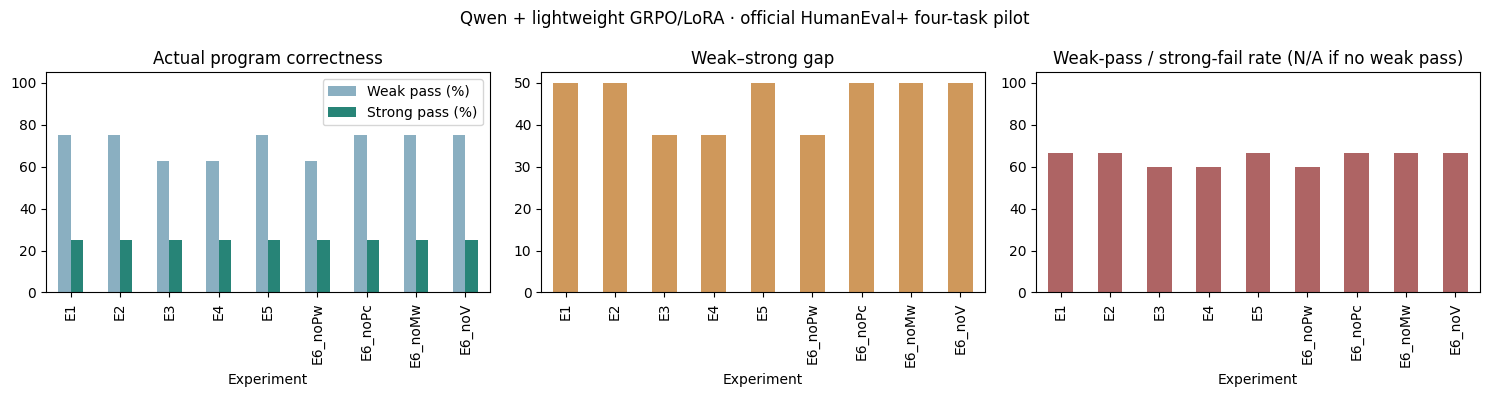

• BAGR strong pass: 25.0%; weak-only GRPO: 25.0% (+0.0 pp).
• The BAGR weak-to-strong gap changes by +0.0 pp relative to weak-only GRPO.
• This run does not establish an improvement in strong correctness; report this outcome as measured.
• Policy-aware versus static challenges: strong pass changes by +0.0 pp under identical reward weights.
• The E6 rows show measured component ablations. All methods used the same seeded LoRA initialization and 10 scheduled training steps; applied updates and AMP skips are in training_efficiency.csv.
• Four tasks and one seed cannot establish statistical significance or unseen-task generalization. Larger experiments are needed before broader claims.


In [24]:
frame=pd.DataFrame(comparison).set_index('Experiment')
figure,axes=plt.subplots(1,3,figsize=(15,4))
frame[['Weak pass (%)','Strong pass (%)']].plot.bar(ax=axes[0],color=['#8aafc1','#278477'])
axes[0].set_ylim(0,105);axes[0].set_title('Actual program correctness')
frame['Gap (pp)'].plot.bar(ax=axes[1],color='#cf985b');axes[1].axhline(0,color='black',linewidth=.7)
axes[1].set_title('Weak–strong gap')
frame['Hack rate (%)'].plot.bar(ax=axes[2],color='#ae6464');axes[2].set_ylim(0,105)
axes[2].set_title('Weak-pass / strong-fail rate (N/A if no weak pass)')
figure.suptitle('Qwen + lightweight GRPO/LoRA · official HumanEval+ four-task pilot')
figure.tight_layout();figure.savefig(OUTPUT_DIR/'figures'/'model_comparison.png',dpi=150);plt.show()

lookup={row['Experiment']:row for row in comparison}
weak,bagr=lookup['E2'],lookup['E5']
delta=bagr['Strong pass (%)']-weak['Strong pass (%)']
gap_delta=bagr['Gap (pp)']-weak['Gap (pp)']
reasons=[f'BAGR strong pass: {bagr["Strong pass (%)"]:.1f}%; weak-only GRPO: {weak["Strong pass (%)"]:.1f}% ({delta:+.1f} pp).',
         f'The BAGR weak-to-strong gap changes by {gap_delta:+.1f} pp relative to weak-only GRPO.']
if delta>0 and gap_delta<=0:
    reasons.append('This pilot shows higher strong correctness with no larger verifier gap.')
elif delta<=0:
    reasons.append('This run does not establish an improvement in strong correctness; report this outcome as measured.')
else:
    reasons.append('Strong correctness improves, but the verifier gap does not improve in this run.')
if weak['Hack rate (%)'] is None or bagr['Hack rate (%)'] is None:
    reasons.append('A conditional hack rate is undefined because one of the policies has no weak passes.')
elif bagr['Hack rate (%)']<weak['Hack rate (%)'] and bagr['Weak pass (%)']<weak['Weak pass (%)']:
    reasons.append('The lower hack rate coincides with fewer weak passes; do not interpret it alone as better correctness.')
static,adaptive=lookup['E3'],lookup['E4']
reasons.append(f'Policy-aware versus static challenges: strong pass changes by {adaptive["Strong pass (%)"]-static["Strong pass (%)"]:+.1f} pp under identical reward weights.')
reasons.append('The E6 rows show measured component ablations. All methods used the same seeded LoRA initialization and 10 scheduled training steps; applied updates and AMP skips are in training_efficiency.csv.')
if any(not row['Adapter changed'] or row['AMP-skipped updates'] for row in training_rows):
    reasons.append('Some runs had unchanged adapters or skipped optimizer updates. Check training efficiency and reward variance before attributing score differences to learning.')
reasons.append('Four tasks and one seed cannot establish statistical significance or unseen-task generalization. Larger experiments are needed before broader claims.')
for reason in reasons:
    print('•',reason)
save_json('results/reasoning.json',reasons)
failures=[row for row in evaluation_rows if row['weak_pass_strong_fail']]
save_csv('results/weak_pass_strong_fail.csv',failures)

In [25]:
report='# BAGR lightweight RL experiment report\n\n'
report+=f'Model: {MODEL_NAME}; commit: {MODEL_REVISION}.\n\n'
report+=f'Tasks: {TASK_IDS}. Seed: {SEED}. Steps per trained experiment: {STAGES*STEPS_PER_STAGE}.\n\n'
report+=f'Device: {DEVICE_NAME}; base dtype: {MODEL_DTYPE}.\n\n'
report+='Two five-step GRPO stages with matching optimizer restarts; one small model in memory at a time.\n\n'
report+=f'Independent official HumanEval+ dataset hash: {official["dataset_hash"]}.\n\n'
report+=f'Evaluation platform adapter: {official["platform_adapter"]}.\n\n'
report+='## Measured results and reasoning\n\n'+'\n\n'.join(reasons)+'\n\n'
report+='See results/model_comparison.csv, training_efficiency.csv, per_program_results.csv, and figures/model_comparison.png.\n'
(OUTPUT_DIR/'results'/'REPORT.md').write_text(report,encoding='utf-8')
print('Completed actual RL and official evaluation pipeline.')
print('Report:',(OUTPUT_DIR/'results'/'REPORT.md').resolve())
print('Adapters:',(OUTPUT_DIR/'checkpoints').resolve())
print('Charts:',(OUTPUT_DIR/'figures').resolve())

Completed actual RL and official evaluation pipeline.
Report: /content/BAGR_project_results/20261101_165355_250279/results/REPORT.md
Adapters: /content/BAGR_project_results/20261101_165355_250279/checkpoints
Charts: /content/BAGR_project_results/20261101_165355_250279/figures
